In [1]:
import pandas as pd
import numpy as np

# 1. Load the A/B test data
ab = pd.read_csv("../data/raw/ab_data.csv")

# 2. Basic shape and structure
print("Shape (rows, columns):", ab.shape)
print("\nColumns and types:")
print(ab.dtypes)

# 3. Date range of the test
ab["timestamp"] = pd.to_datetime(ab["timestamp"])
print("\nTest period:", ab["timestamp"].min(), "to", ab["timestamp"].max())

# 4. How many users, and how were they split?
print("\nUnique users:", ab["user_id"].nunique())
print("\nGroup vs landing page (should be control = old_page, treatment = new_page):")
print(pd.crosstab(ab["group"], ab["landing_page"], margins=True))

# 5. Overall conversion rate
print(f"\nOverall conversion rate: {ab['converted'].mean():.4%}")

ab.head()

Shape (rows, columns): (294478, 5)

Columns and types:
user_id         int64
timestamp         str
group             str
landing_page      str
converted       int64
dtype: object

Test period: 2017-01-02 13:42:05.378582 to 2017-01-24 13:41:54.460509

Unique users: 290584

Group vs landing page (should be control = old_page, treatment = new_page):
landing_page  new_page  old_page     All
group                                   
control           1928    145274  147202
treatment       145311      1965  147276
All             147239    147239  294478

Overall conversion rate: 11.9659%


,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


In [2]:
# 1. Flag rows where the page shown does not match the user's group
ab["mismatch"] = (
    ((ab["group"] == "control")   & (ab["landing_page"] == "new_page")) |
    ((ab["group"] == "treatment") & (ab["landing_page"] == "old_page"))
)

# 2. Profile each user: how many rows, groups, pages, and any mismatch?
per_user = ab.groupby("user_id").agg(
    rows=("user_id", "size"),
    groups=("group", "nunique"),
    pages=("landing_page", "nunique"),
    any_mismatch=("mismatch", "max"),
)

contaminated = per_user[(per_user["any_mismatch"]) | (per_user["groups"] > 1) | (per_user["pages"] > 1)].index
dup_clean_users = per_user[(per_user["rows"] > 1) & ~per_user.index.isin(contaminated)].index

print("Mismatched rows:", ab["mismatch"].sum())
print("Users appearing more than once:", (per_user["rows"] > 1).sum())
print("Contaminated users (wrong page, or both groups/pages):", len(contaminated))
print("Remaining users still duplicated (same group & page):", len(dup_clean_users), list(dup_clean_users))

# 3. Clean dataset: drop contaminated users, keep each remaining user's FIRST visit
clean = (
    ab[~ab["user_id"].isin(contaminated)]
    .sort_values("timestamp")
    .drop_duplicates(subset="user_id", keep="first")
    .drop(columns="mismatch")
    .reset_index(drop=True)
)

# 4. Checks
print("\nClean rows:", len(clean), "| Unique users:", clean["user_id"].nunique())
print("\nClean crosstab (should have no mismatches):")
print(pd.crosstab(clean["group"], clean["landing_page"], margins=True))
print(f"\nUsers removed in total: {ab['user_id'].nunique() - len(clean):,} "
      f"({(ab['user_id'].nunique() - len(clean)) / ab['user_id'].nunique():.2%} of all users)")

# 5. Save the clean data
clean.to_csv("../data/processed/ab_clean.csv", index=False)
print("\nSaved: ../data/processed/ab_clean.csv")

Mismatched rows: 3893
Users appearing more than once: 3894
Contaminated users (wrong page, or both groups/pages): 3893
Remaining users still duplicated (same group & page): 1 [773192]

Clean rows: 286691 | Unique users: 286691

Clean crosstab (should have no mismatches):
landing_page  new_page  old_page     All
group                                   
control              0    143293  143293
treatment       143398         0  143398
All             143398    143293  286691

Users removed in total: 3,893 (1.34% of all users)

Saved: ../data/processed/ab_clean.csv


In [3]:
from scipy import stats

# 1. Overall SRM check: chi-square test of observed group sizes vs an expected 50/50 split
observed = clean["group"].value_counts().reindex(["control", "treatment"])
expected = [len(clean) / 2] * 2
chi2, p_srm = stats.chisquare(f_obs=observed, f_exp=expected)

print("Observed users per group:")
print(observed.to_string())
print(f"\nTreatment share: {observed['treatment'] / observed.sum():.4%} (expected 50%)")
print(f"Chi-square = {chi2:.4f}, p-value = {p_srm:.4f}")
print("SRM verdict:", "FAIL - split is broken, do not trust the test" if p_srm < 0.001 else "PASS - the 50/50 split is fine")

# 2. Day-by-day split (a bug could appear on only some days)
clean["date"] = clean["timestamp"].dt.date
daily = clean.pivot_table(index="date", columns="group", values="user_id", aggfunc="count")
daily["treatment_share_pct"] = (100 * daily["treatment"] / (daily["control"] + daily["treatment"])).round(2)

print(f"\nDays in test: {len(daily)}")
print(f"Daily treatment share ranges from {daily['treatment_share_pct'].min()}% to {daily['treatment_share_pct'].max()}%")
daily

Observed users per group:
group
control      143293
treatment    143398

Treatment share: 50.0183% (expected 50%)
Chi-square = 0.0385, p-value = 0.8445
SRM verdict: PASS - the 50/50 split is fine

Days in test: 23
Daily treatment share ranges from 49.24% to 50.62%


group,control,treatment,treatment_share_pct
date,,,
2017-01-02,2813,2818,50.04
2017-01-03,6494,6531,50.14
2017-01-04,6481,6448,49.87
2017-01-05,6330,6418,50.35
2017-01-06,6518,6650,50.50
2017-01-07,6493,6520,50.10
2017-01-08,6602,6629,50.10
2017-01-09,6538,6527,49.96
2017-01-10,6575,6609,50.13


In [4]:
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

# 1. Conversion by group
summary = clean.groupby("group").agg(users=("user_id", "count"), conversions=("converted", "sum"))
summary["conversion_rate_pct"] = (100 * summary["conversions"] / summary["users"]).round(4)
print(summary, "\n")

n_t, x_t = summary.loc["treatment", "users"], summary.loc["treatment", "conversions"]
n_c, x_c = summary.loc["control", "users"], summary.loc["control", "conversions"]
p_t, p_c = x_t / n_t, x_c / n_c

# 2. Two-proportion z-test (two-sided): treatment vs control
z_stat, p_value = proportions_ztest(count=[x_t, x_c], nobs=[n_t, n_c], alternative="two-sided")

# 3. 95% confidence interval for the difference (treatment - control)
ci_low, ci_high = confint_proportions_2indep(x_t, n_t, x_c, n_c, method="wald", compare="diff")

diff = p_t - p_c
print(f"Control conversion   : {p_c:.4%}")
print(f"Treatment conversion : {p_t:.4%}")
print(f"Absolute difference  : {diff * 100:+.3f} percentage points")
print(f"Relative lift        : {diff / p_c:+.2%}")
print(f"\nz = {z_stat:.3f}, p-value = {p_value:.4f}")
print(f"95% CI for the difference: {ci_low * 100:+.3f} to {ci_high * 100:+.3f} percentage points")
print(f"95% CI as relative lift  : {ci_low / p_c:+.2%} to {ci_high / p_c:+.2%}")
print("\nStatistically significant at 5%?", "YES" if p_value < 0.05 else "NO")

            users  conversions  conversion_rate_pct
group                                              
control    143293        17220              12.0173
treatment  143398        17025              11.8726 

Control conversion   : 12.0173%
Treatment conversion : 11.8726%
Absolute difference  : -0.145 percentage points
Relative lift        : -1.20%

z = -1.195, p-value = 0.2320
95% CI for the difference: -0.382 to +0.093 percentage points
95% CI as relative lift  : -3.18% to +0.77%

Statistically significant at 5%? NO


Practical threshold : +2% relative lift (= +0.240 pp)
Best case from 95% CI: +0.77% relative
Meaningful lift ruled out? YES - even the best case is below the threshold

Days where the new page converted better: 9 of 23

Effect by period (novelty check):
    period  users  control_pct  treatment_pct  diff_pp  p_value
  Days 1-7  83745       11.919         11.784   -0.135    0.546
 Days 8-14  91381       11.925         11.817   -0.108    0.614
Days 15-23 111565       12.166         11.985   -0.181    0.353


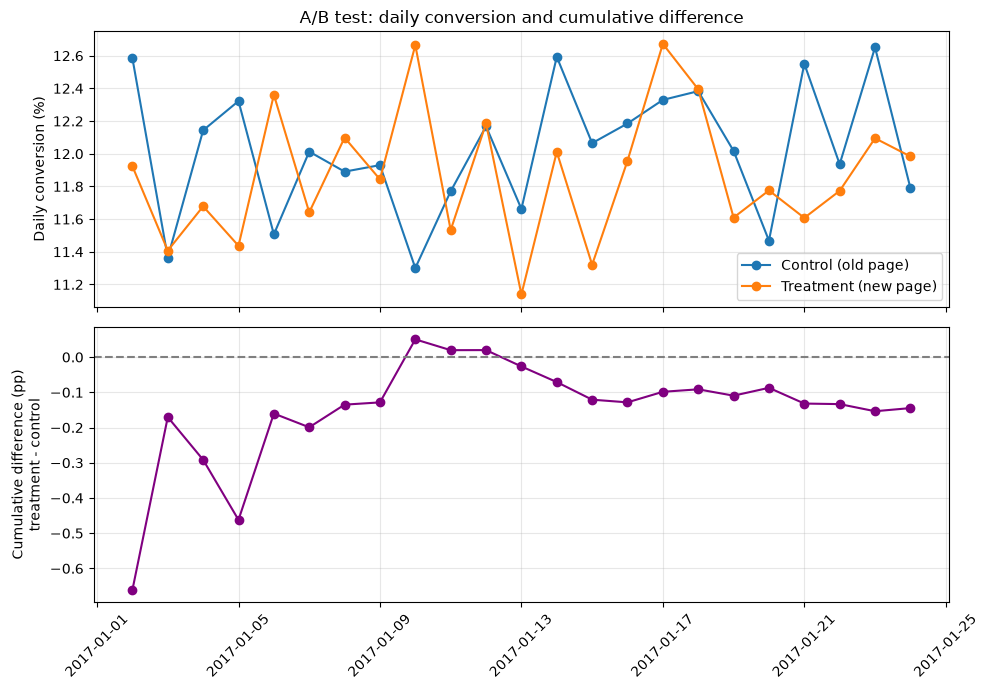

In [5]:
import matplotlib.pyplot as plt

# A) Practical significance: can the new page deliver a lift worth launching?
PRACTICAL_LIFT = 0.02   # minimum relative lift worth launching (+2%)
print(f"Practical threshold : +{PRACTICAL_LIFT:.0%} relative lift (= {PRACTICAL_LIFT * p_c * 100:+.3f} pp)")
print(f"Best case from 95% CI: {ci_high / p_c:+.2%} relative")
print("Meaningful lift ruled out?", "YES - even the best case is below the threshold"
      if ci_high / p_c < PRACTICAL_LIFT else "NO - a meaningful lift is still possible")

# B1) Daily conversion and daily difference
daily_conv = clean.pivot_table(index="date", columns="group", values="converted", aggfunc="mean") * 100
daily_conv["diff_pp"] = daily_conv["treatment"] - daily_conv["control"]
print(f"\nDays where the new page converted better: {(daily_conv['diff_pp'] > 0).sum()} of {len(daily_conv)}")

# B2) Cumulative difference: how the overall gap settles as data accumulates
cum = clean.groupby(["date", "group"])["converted"].agg(["sum", "count"]).unstack().cumsum()
cum_diff_pp = (cum[("sum", "treatment")] / cum[("count", "treatment")]
               - cum[("sum", "control")] / cum[("count", "control")]) * 100

# B3) Novelty check: the effect in three periods of the test
start = clean["timestamp"].min().normalize()
clean["test_day"] = (clean["timestamp"].dt.normalize() - start).dt.days + 1
clean["period"] = pd.cut(clean["test_day"], bins=[0, 7, 14, 23], labels=["Days 1-7", "Days 8-14", "Days 15-23"])

rows = []
for period, g in clean.groupby("period", observed=True):
    t, c = g[g["group"] == "treatment"], g[g["group"] == "control"]
    _, p = proportions_ztest([t["converted"].sum(), c["converted"].sum()], [len(t), len(c)])
    rows.append({
        "period": period,
        "users": len(g),
        "control_pct": round(100 * c["converted"].mean(), 3),
        "treatment_pct": round(100 * t["converted"].mean(), 3),
        "diff_pp": round(100 * (t["converted"].mean() - c["converted"].mean()), 3),
        "p_value": round(p, 3),
    })
periods = pd.DataFrame(rows)
print("\nEffect by period (novelty check):")
print(periods.to_string(index=False))

# Chart: daily conversion (top) and cumulative difference (bottom)
fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
ax[0].plot(daily_conv.index, daily_conv["control"], marker="o", label="Control (old page)")
ax[0].plot(daily_conv.index, daily_conv["treatment"], marker="o", label="Treatment (new page)")
ax[0].set_ylabel("Daily conversion (%)")
ax[0].set_title("A/B test: daily conversion and cumulative difference")
ax[0].legend()
ax[0].grid(alpha=0.3)
ax[1].plot(cum_diff_pp.index, cum_diff_pp, color="purple", marker="o")
ax[1].axhline(0, color="grey", linestyle="--")
ax[1].set_ylabel("Cumulative difference (pp)\ntreatment - control")
ax[1].grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../images/ab_daily_stability.png", dpi=150)
plt.show()

In [6]:
import math
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

power_calc = NormalIndPower()
ALPHA, POWER = 0.05, 0.80

def n_per_group(p_base, p_target):
    """Users (or sessions) needed in EACH group to detect p_base -> p_target."""
    es = proportion_effectsize(p_target, p_base)
    return math.ceil(power_calc.solve_power(effect_size=abs(es), alpha=ALPHA, power=POWER,
                                            ratio=1, alternative="two-sided"))

# 1) Minimum Detectable Effect (MDE) of THIS A/B test
n_each = len(clean) / 2
h = power_calc.solve_power(nobs1=n_each, alpha=ALPHA, power=POWER, ratio=1, alternative="two-sided")
p_mde = math.sin(math.asin(math.sqrt(p_c)) + h / 2) ** 2
print(f"This test ({n_each:,.0f} users per group, baseline {p_c:.2%}) could reliably detect:")
print(f"  MDE = {(p_mde - p_c) * 100:+.3f} pp  ({(p_mde - p_c) / p_c:+.2%} relative) at 80% power\n")

# 2) Planning tests for the Google Merchandise Store (rates and traffic from the GA4 analysis)
DAYS = 92  # 1 Nov 2020 - 31 Jan 2021
scenarios = [
    # (test, unit, baseline, target, units per day)
    ("Store-wide conversion +5% rel",   "sessions",               0.0134, 0.0134 * 1.05, 360129 / DAYS),
    ("Store-wide conversion +10% rel",  "sessions",               0.0134, 0.0134 * 1.10, 360129 / DAYS),
    ("Store-wide conversion +20% rel",  "sessions",               0.0134, 0.0134 * 1.20, 360129 / DAYS),
    ("Product page: view->cart +2 pts", "sessions viewing items", 0.197,  0.217,         77020 / DAYS),
    ("Product page: view->cart +5 pts", "sessions viewing items", 0.197,  0.247,         77020 / DAYS),
    ("Shipping step: ship->pay +5 pts", "sessions at shipping",   0.614,  0.664,         11105 / DAYS),
]

plan = []
for name, unit, base, target, per_day in scenarios:
    n = n_per_group(base, target)
    plan.append({
        "test": name,
        "unit": unit,
        "baseline_pct": round(base * 100, 2),
        "target_pct": round(target * 100, 2),
        "per_group": n,
        "total": 2 * n,
        "units_per_day": round(per_day),
        "days_needed": math.ceil(2 * n / per_day),
    })

plan_df = pd.DataFrame(plan)
plan_df.to_csv("../data/processed/ab_sample_size_plan.csv", index=False)
plan_df

This test (143,346 users per group, baseline 12.02%) could reliably detect:
  MDE = +0.342 pp  (+2.85% relative) at 80% power



,test,unit,baseline_pct,target_pct,per_group,total,units_per_day,days_needed
0,Store-wide conversion +5% rel,sessions,1.34,1.41,473637,947274,3914,242
1,Store-wide conversion +10% rel,sessions,1.34,1.47,121206,242412,3914,62
2,Store-wide conversion +20% rel,sessions,1.34,1.61,31676,63352,3914,17
3,Product page: view->cart +2 pts,sessions viewing items,19.70,21.70,6439,12878,837,16
4,Product page: view->cart +5 pts,sessions viewing items,19.70,24.70,1082,2164,837,3
5,Shipping step: ship->pay +5 pts,sessions at shipping,61.40,66.40,1447,2894,121,24


In [7]:
from importlib.metadata import version

# Python libraries used in this project (A/B test notebook), with exact installed versions
packages = ["pandas", "numpy", "scipy", "statsmodels", "matplotlib", "jupyter", "ipykernel"]

lines = [f"{p}=={version(p)}" for p in packages]
with open("../requirements.txt", "w") as f:
    f.write("\n".join(lines) + "\n")

print("\n".join(lines))

pandas==3.1.0
numpy==2.5.4
scipy==1.18.1
statsmodels==0.15.0
matplotlib==3.11.2
jupyter==1.1.1
ipykernel==7.4.0
